Assignement 3

In [13]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
from scipy.sparse.linalg import eigsh
import graph_tool.all as gt

1.

**(a)** Figure 2 of Guimerà et al. (2004) plots the maximum modularity of Barabási–Albert networks against size $S$ for several $m$, with the prediction $M_{SF}=\big(a+\frac{1-a}{m}\big)\big(1-\frac{2}{\sqrt S}\big)$, $a=0.165$. I use the best of 5 Louvain runs per graph (the paper uses simulated annealing), averaged over 10 graphs.

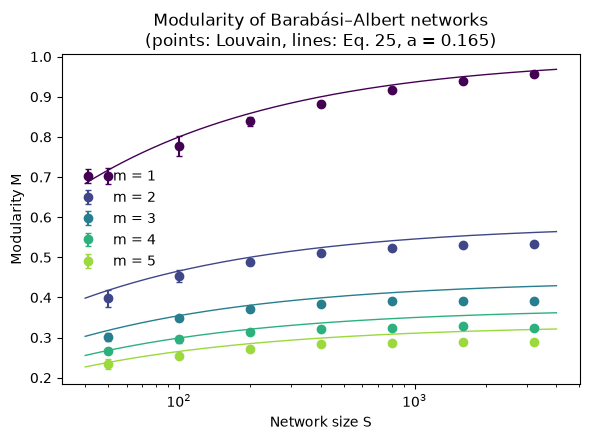

m=1: S=50: 0.703 (0.717)  S=100: 0.778 (0.800)  S=200: 0.839 (0.859)  S=400: 0.883 (0.900)  S=800: 0.916 (0.929)  S=1600: 0.940 (0.950)  S=3200: 0.957 (0.965)
m=2: S=50: 0.397 (0.418)  S=100: 0.454 (0.466)  S=200: 0.488 (0.500)  S=400: 0.510 (0.524)  S=800: 0.523 (0.541)  S=1600: 0.530 (0.553)  S=3200: 0.534 (0.562)
m=3: S=50: 0.302 (0.318)  S=100: 0.348 (0.355)  S=200: 0.371 (0.381)  S=400: 0.384 (0.399)  S=800: 0.391 (0.412)  S=1600: 0.392 (0.421)  S=3200: 0.392 (0.428)
m=4: S=50: 0.267 (0.268)  S=100: 0.296 (0.299)  S=200: 0.315 (0.321)  S=400: 0.320 (0.336)  S=800: 0.324 (0.347)  S=1600: 0.328 (0.355)  S=3200: 0.323 (0.361)
m=5: S=50: 0.234 (0.238)  S=100: 0.255 (0.266)  S=200: 0.272 (0.285)  S=400: 0.283 (0.299)  S=800: 0.287 (0.309)  S=1600: 0.290 (0.315)  S=3200: 0.288 (0.320)


In [14]:
def max_modularity(G, n_runs=5, seed=None):
    rng = np.random.default_rng(seed)
    best = -1
    for _ in range(n_runs):
        part = nx.community.louvain_communities(G, seed=int(rng.integers(1e9)))
        best = max(best, nx.community.modularity(G, part))
    return best

def M_SF(S, m, a=0.165):
    return (a + (1 - a) / m) * (1 - 2 / np.sqrt(S))

S_list = [50, 100, 200, 400, 800, 1600, 3200]
m_list = [1, 2, 3, 4, 5]
n_graphs = 10
res = {}
for m in m_list:
    for S in S_list:
        vals = [max_modularity(nx.barabasi_albert_graph(S, m, seed=1000*m+i), seed=i) for i in range(n_graphs)]
        res[(m, S)] = (np.mean(vals), np.std(vals))

fig, ax = plt.subplots(figsize=(6, 4.5))
colors = plt.cm.viridis(np.linspace(0, 0.85, len(m_list)))
S_grid = np.logspace(np.log10(40), np.log10(4000), 200)
for c, m in zip(colors, m_list):
    mu = [res[(m, S)][0] for S in S_list]; sd = [res[(m, S)][1] for S in S_list]
    ax.errorbar(S_list, mu, yerr=sd, fmt="o", color=c, label=f"m = {m}", capsize=2)
    ax.plot(S_grid, M_SF(S_grid, m), "-", color=c, lw=1)
ax.set_xscale("log"); ax.set_xlabel("Network size S"); ax.set_ylabel("Modularity M")
ax.set_title("Modularity of Barabási–Albert networks\n(points: Louvain, lines: Eq. 25, a = 0.165)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# simulated vs. predicted values
for m in m_list:
    print(f"m={m}: " + "  ".join(f"S={S}: {res[(m,S)][0]:.3f} ({M_SF(S,m):.3f})" for S in S_list))

**Comment.** BA networks have no real community structure, but their maximum modularity is still high, from about 0.25 ($m=5$) to about 0.95 ($m=1$). These values are as high as what people usually call strong community structure. Modularity also goes up with $S$ and goes down with $m$, so it depends on the size and density of the network, not only on groups. Louvain is a little below the curves for large $S$, so the true maximum is even higher.

The reason is that the expected modularity of one fixed random partition is about 0, but when we search over a huge number of partitions and keep the best one, we pick up random fluctuations. So modularity maximization can find "communities" in pure noise.

This means a high $Q$ alone does not prove that a network has communities, and we cannot compare $Q$ between networks of different size or density. We should compare it with $Q$ from randomized networks with the same degrees, or use a statistical method like the SBM in the next parts.

**(b)** I load polblogs from Netzschleuder, keep the largest component, and fit both models with exactly two blocks (`B_min=2`, `B_max=2`). To understand the blocks, I print the size and mean degree of each block, and the share of conservative blogs in it (`value` is 0 for liberal and 1 for conservative).

In [15]:
g = gt.collection.ns["polblogs"]
g = gt.extract_largest_component(g, directed=False)
g = gt.Graph(g, prune=True)          # make a real copy of the component
pos = g.vp._pos                      # layout that comes with the dataset
party = np.array(g.vp.value.a)       # 0 = liberal, 1 = conservative
degree = g.get_total_degrees(g.get_vertices())
print(g.num_vertices(), "nodes")

gt.seed_rng(42)
np.random.seed(42)
two_blocks = dict(B_min=2, B_max=2)
state_ndc = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=False), multilevel_mcmc_args=two_blocks)
state_dc = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True), multilevel_mcmc_args=two_blocks)

for name, state in [("non-degree-corrected", state_ndc), ("degree-corrected", state_dc)]:
    print(name)
    b = np.array(state.get_blocks().a)
    for block in np.unique(b):
        in_block = (b == block)
        print(f"   block {block}: {in_block.sum()} nodes, mean degree {degree[in_block].mean():.1f}, "
              f"{party[in_block].mean():.0%} conservative")

1222 nodes
non-degree-corrected
   block 1130: 347 nodes, mean degree 83.6, 50% conservative
   block 1148: 875 nodes, mean degree 10.5, 53% conservative
degree-corrected
   block 502: 560 nodes, mean degree 32.1, 3% conservative
   block 724: 662 nodes, mean degree 30.5, 94% conservative


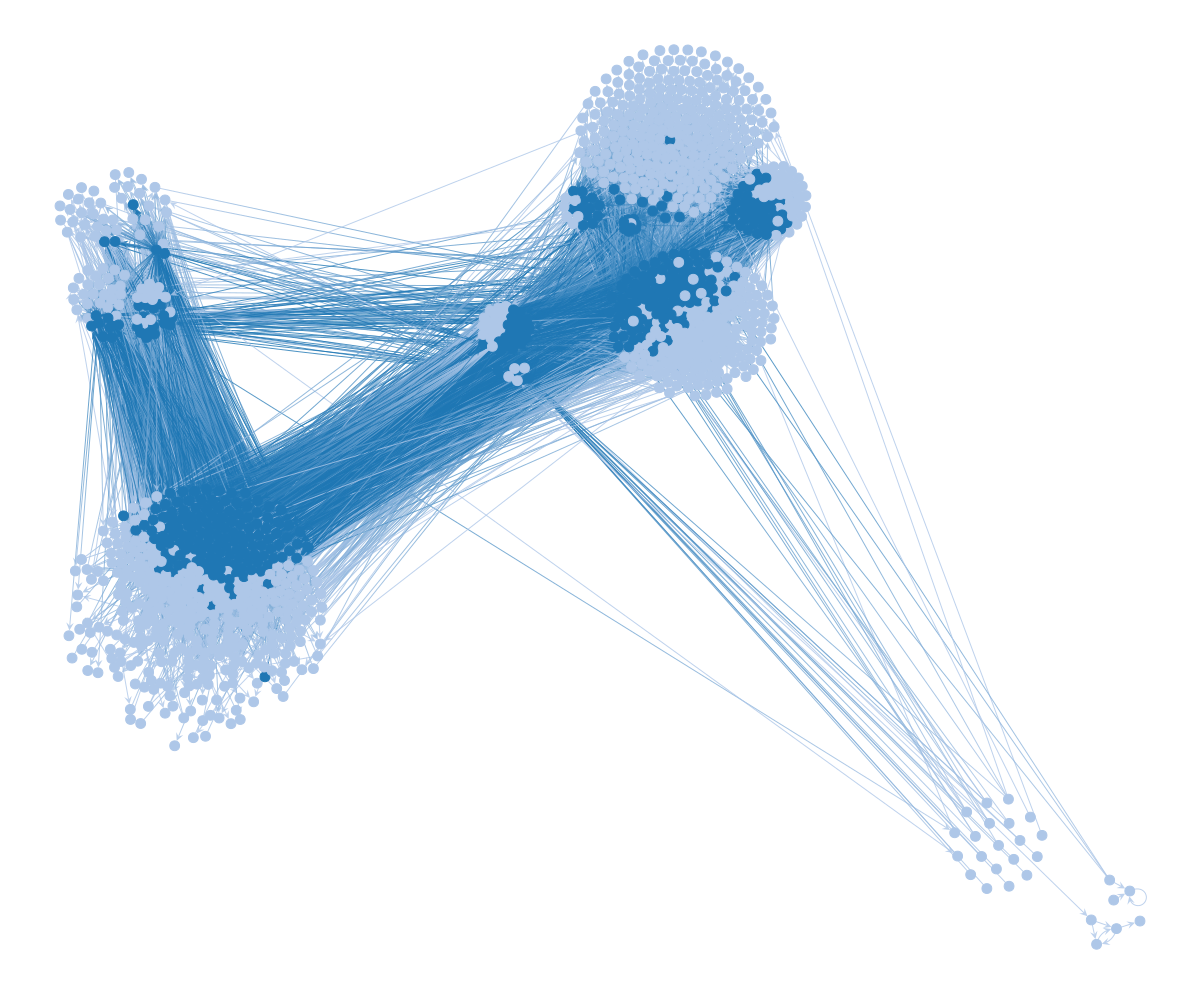

In [16]:
# non-degree-corrected SBM, B = 2
state_ndc.draw(pos=pos);

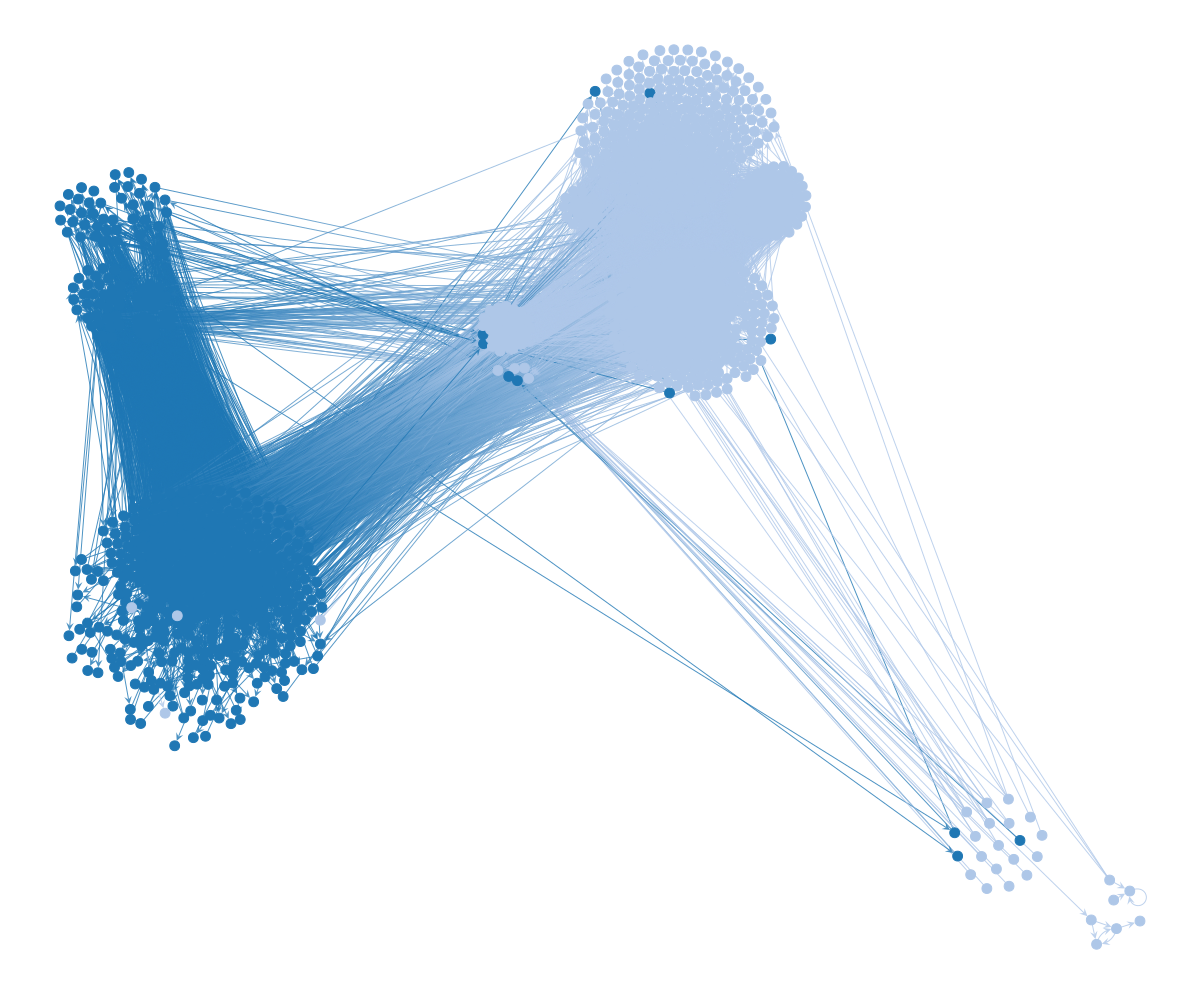

In [17]:
# degree-corrected SBM, B = 2
state_dc.draw(pos=pos);

The two models give very different partitions. The non-degree-corrected SBM puts 347 high-degree blogs (mean degree about 84) in one block and 875 low-degree blogs (mean degree about 10) in the other. Both blocks are about half liberal and half conservative, so this split has nothing to do with politics. The degree-corrected SBM gives two blocks with similar mean degree, and one block is about 94% conservative while the other is about 97% liberal. So it finds the political divide.

The reason is that the plain SBM assumes that nodes in the same block have about the same degree. Polblogs has a few hubs and many low-degree blogs, so with only two blocks the plain SBM uses the blocks to separate hubs from everyone else. The degree-corrected SBM lets each node keep its own degree, so the blocks only need to explain who connects to whom, and then the political split shows up.

**(c) i.** Description length of the two fits from (b) (graph-tool's `entropy()` is in nats).

In [18]:
print("Non-degree-corrected DL:", round(state_ndc.entropy(), 1))
print("Degree-corrected DL:    ", round(state_dc.entropy(), 1))

Non-degree-corrected DL: 83348.2
Degree-corrected DL:     63427.4


The degree-corrected model has a much smaller description length (about 63,400 vs 83,300 nats). So it describes the network much better, even though it also has to describe every node's degree.

deg_corr=False: DL start 103103, end 64607, blocks at the end = 15
deg_corr=True: DL start 71935, end 62284, blocks at the end = 5


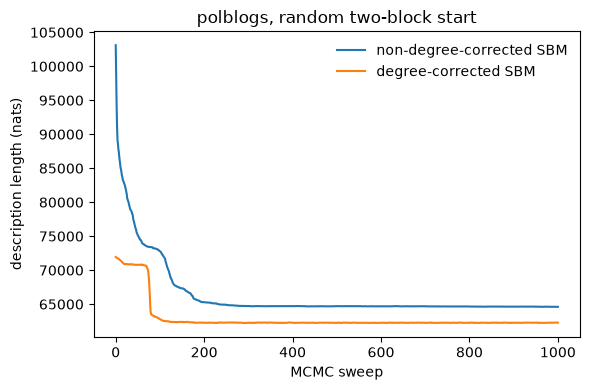

In [19]:
n_sweeps = 1000
curves = {}
for dc in [False, True]:
    np.random.seed(0)
    b = np.random.randint(0, 2, g.num_vertices())          # random two-block start
    state = gt.BlockState(g, b=b, deg_corr=dc)
    dl = [state.entropy()]
    for i in range(n_sweeps):
        state.mcmc_sweep(niter=1)                           # number of blocks is free to change
        dl.append(state.entropy())
    curves[dc] = dl
    n_blocks = len(np.unique(state.get_blocks().a))
    print(f"deg_corr={dc}: DL start {dl[0]:.0f}, end {dl[-1]:.0f}, blocks at the end = {n_blocks}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curves[False], label="non-degree-corrected SBM")
ax.plot(curves[True], label="degree-corrected SBM")
ax.set_xlabel("MCMC sweep")
ax.set_ylabel("description length (nats)")
ax.set_title("polblogs, random two-block start")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**(c) ii.** Both curves drop quickly in the first 100–200 sweeps and then stay almost flat, so the chain settles well before 1,000 sweeps. The drops are not smooth. Sometimes the curve is flat for a while and then falls suddenly (for example the degree-corrected curve around sweep 80), which is when the chain finds a better grouping for many nodes at once.

The degree-corrected model starts lower and ends lower (about 62,300 vs 64,600 nats). Since the number of blocks is free here, the non-degree-corrected model ends with many more blocks (15 vs 5). It needs the extra blocks to deal with the different degrees, but it still cannot reach the description length of the degree-corrected model. This is only one run from one random start, so the exact numbers would change a little with another seed.

**(d)** Figure 7 of Peixoto (arXiv:1705.10225) shows the same experiment on polblogs with $B=2$. The SBM splits the network into low- and high-degree groups, and the DC-SBM splits it into the two political sides. This is the same as what I found in (b), so my approach is on the right track.

*Intuition.* In the plain SBM, the chance of an edge only depends on the blocks of the two nodes, so all nodes in a block are expected to have about the same degree. Real networks have hubs and many low-degree nodes, so the plain SBM ends up using its blocks to describe degrees. Degree correction takes each node's degree as given and asks which blocks the edges connect, beyond what the degrees already explain. This is similar to the degree-based null model in modularity.

*Formalism.* In the microcanonical DC-SBM, the network is generated in three steps (Figure 8). Given the partition $b$,

1. choose the number of edges between each pair of blocks, $e_{rs}$,
2. choose the degree $k_i$ of each node, so that the degrees in block $r$ add up to $e_r$,
3. place the edges at random so that every node has degree $k_i$ and every pair of blocks has $e_{rs}$ edges.

So $P(A\mid b)=P(A\mid k,e,b)\,P(k\mid e,b)\,P(e\mid b)$, and the description length is $\Sigma=-\log_2 P(A,b)$. The non-degree-corrected SBM does not have step 2. Degree correction has a cost, because the degrees also have to be described through $P(k\mid e,b)$.

*Model selection.* We pick the model with the smaller description length. If we believe both models equally beforehand, the posterior odds ratio between two models is $\Lambda = 2^{-\Delta\Sigma}$ (or $e^{-\Delta\Sigma}$ in nats). In (c) the degree-corrected fit is about 20,000 nats shorter, so it is about $e^{20000}$ times more likely than the plain SBM. If all nodes had similar degrees, the extra cost of describing the degrees would not pay off, and the plain SBM could win.

2.

**(a)** The hitting time $H_{ij}$ is the average number of steps a random walker needs to reach $j$ for the first time when it starts at $i$. The commute time is the round trip, $C_{ij}=H_{ij}+H_{ji}$. The two directions are usually different, so I compute both.

To get $H_{ij}$, I think about the first step. Let $P=D^{-1}A$ be the transition matrix. If the walker is already at $j$, then $H_{jj}=0$. Otherwise it takes one step, and then still needs the hitting time from the new node,

$$H_{ij}=1+\sum_k P_{ik}H_{kj}\quad (i\neq j).$$

If I remove row and column $j$ from $P$ (call it $P'$), this is the linear system $(I-P')\,h=\mathbf{1}$, which gives the hitting times from all nodes to $j$ at once.

In [20]:
def hitting_times_to(A, j):
    # hitting time from every node to node j
    # H[j] = 0, and for i != j: H[i] = 1 + sum_k P[i,k] * H[k]
    n = len(A)
    P = A / A.sum(axis=1, keepdims=True)              # transition matrix
    P_small = np.delete(np.delete(P, j, axis=0), j, axis=1)   # remove node j
    h = np.linalg.solve(np.eye(n - 1) - P_small, np.ones(n - 1))
    H = np.insert(h, j, 0)                            # put H[j] = 0 back
    return H


def commute_time(G, i, j):
    # commute time = H(i -> j) + H(j -> i)
    A = nx.to_numpy_array(G, nodelist=range(G.number_of_nodes()), weight=None)   # unweighted
    return hitting_times_to(A, j)[i] + hitting_times_to(A, i)[j]


# test on the karate club graph
G = nx.karate_club_graph()
rng = np.random.default_rng(1)
for _ in range(3):
    i, j = rng.choice(G.number_of_nodes(), 2, replace=False)
    print(f"nodes {i} and {j} (degrees {G.degree(i)}, {G.degree(j)}): commute time = {commute_time(G, i, j):.2f}")

nodes 15 and 17 (degrees 2, 2): commute time = 188.38
nodes 1 and 31 (degrees 9, 6): commute time = 64.67
nodes 32 and 27 (degrees 12, 4): commute time = 62.90


The pair with the longest commute time (nodes 15 and 17) is the pair where both nodes have degree 2, because low-degree nodes are hard for a random walker to find. Note that `karate_club_graph` has edge weights in new versions of networkx, so I set `weight=None` to get the simple unweighted walk.

In [21]:
def mean_commute_time(G):
    # average commute time over all pairs of nodes
    A = nx.to_numpy_array(G, weight=None)
    n = len(A)
    H = np.zeros((n, n))                 # H[i, j] = hitting time from i to j
    for j in range(n):
        H[:, j] = hitting_times_to(A, j)
    C = H + H.T                          # commute times (diagonal is 0)
    return C.sum() / (n * (n - 1))       # mean over all pairs i != j


def largest_component(G):
    return G.subgraph(max(nx.connected_components(G), key=len)).copy()


results = {"ER": [], "BA": []}
mean_inv_k = {"ER": [], "BA": []}
for s in range(10):
    G_er = largest_component(nx.erdos_renyi_graph(500, 8 / 499, seed=s))   # <k> = p (N-1) = 8
    G_ba = largest_component(nx.barabasi_albert_graph(500, 4, seed=s))
    for name, G in [("ER", G_er), ("BA", G_ba)]:
        k = np.array([d for _, d in G.degree()])
        results[name].append(mean_commute_time(G))
        mean_inv_k[name].append(np.mean(1 / k))

for name in ["ER", "BA"]:
    print(name, "mean commute time =", round(np.mean(results[name]), 1),
          " sd =", round(np.std(results[name]), 1), " mean of 1/k =", round(np.mean(mean_inv_k[name]), 3))

ER mean commute time = 1354.8  sd = 25.2  mean of 1/k = 0.145
BA mean commute time = 1585.6  sd = 7.9  mean of 1/k = 0.176


**(b)** The mean commute time is about 1355 for ER networks and about 1586 for BA networks. Both have almost the same number of edges (about 2000), but it takes longer on average to go between two nodes and back in BA networks.

I first expected BA to be faster, because BA networks have hubs and shorter paths. But commute time mostly depends on the degrees of the two end nodes, not on path length. Roughly, $C_{ij}\approx 2m\,(1/k_i+1/k_j)$, so a node with low degree is hard to reach because few edges lead into it. In BA networks most nodes have low degree (around 4 or 5) and only a few are hubs, while in ER networks most nodes have degree close to 8. So the average of $1/k$ is larger in BA (0.176 vs 0.145), and the mean commute time is larger too. The BA values also vary less between samples (sd about 8 vs 25). One reason is that a BA network with $m=4$ always has the same number of edges, while the number of edges in an ER network changes from sample to sample.

3.

**(a) Modularity and its null model.** Modularity $Q$ measures how good a partition of a network into groups is. It compares the number of edges inside the groups with the number we would expect if the edges were placed at random,

$$Q=\frac{1}{2m}\sum_{ij}\left[A_{ij}-\frac{k_i k_j}{2m}\right]\delta(g_i,g_j).$$

$A_{ij}$ is the adjacency matrix, $k_i$ is the degree of node $i$, $m$ is the number of edges, and $\delta(g_i,g_j)=1$ when $i$ and $j$ are in the same group. The term $k_ik_j/2m$ is the null model. It is the expected number of edges between $i$ and $j$ in a random network where every node keeps its degree (the configuration model). $Q$ is high when the groups have many more inside edges than this. We use it to compare partitions and to find communities (Louvain maximizes $Q$).

In [22]:
# ---------- example network: two groups, each with a hub ----------
A_nodes, B_nodes = list(range(0, 8)), list(range(8, 16))
G = nx.Graph()
G.add_edges_from([(0, i) for i in A_nodes[1:]] + [(8, i) for i in B_nodes[1:]])  # hub spokes
G.add_edges_from([(1, 2), (3, 4), (5, 6), (9, 10), (11, 12), (13, 14)])         # within-group
G.add_edges_from([(0, 8), (7, 15)])                                               # between-group
hub_a, hub_b, c, d = 0, 8, 3, 4
deg = dict(G.degree()); m = G.number_of_edges(); two_m = 2 * m
B_hub = 1 - deg[hub_a] * deg[hub_b] / two_m
B_cd = 1 - deg[c] * deg[d] / two_m

# layout: each hub at the centre of its group, the other nodes on a ring
pos = {}
for hub, group, cx in [(hub_a, A_nodes, -1.25), (hub_b, B_nodes, 1.25)]:
    pos[hub] = np.array([cx, 0.0])
    others = [v for v in group if v != hub]
    for k, v in enumerate(others):
        ang = np.pi / 2 + 2 * np.pi * k / len(others) + (0 if cx < 0 else np.pi)
        pos[v] = np.array([cx + np.cos(ang), np.sin(ang)])

**(b) What confused me: why is the expected number of edges $k_ik_j/2m$, and not just the density?**

At first I thought a community is just a group of nodes with many edges between them, so I would compare with the overall density $p$, which is the same for every pair. Then every edge would count the same.

But two hubs are likely to be connected just because both have many edges, not because they are in the same group. If the null model ignored degree, modularity would mostly reward putting hubs together.

The way I understand $k_ik_j/2m$ is with "stubs".

1. Cut every edge in half, so node $i$ has $k_i$ stubs, and there are $2m$ stubs in total.
2. Pair all the stubs at random.
3. One stub of $i$ connects to a stub of $j$ with probability about $k_j/2m$. Node $i$ has $k_i$ stubs, so the expected number of edges between $i$ and $j$ is about $k_i k_j/2m$.

So $A_{ij}-k_ik_j/2m$ measures how surprising an edge is, given the degrees. The most surprising part for me is that $k_ik_j/2m$ can be larger than 1. For two hubs, the null model expects more than one edge, so an edge that really exists can still make a negative contribution to $Q$. An edge between two low-degree nodes is rare by chance, so it counts a lot.

In my flashcard network, $2m=44$, the hubs $a,b$ have $k=8$, and $c,d$ have $k=2$. Then $A_{ab}-k_ak_b/2m=1-64/44=-0.45$ and $A_{cd}-k_ck_d/2m=1-4/44=+0.91$. Below I check the formula by making many random networks with the same degrees and counting the edges between these pairs.

In [23]:
# Check E[A_ij] = k_i k_j / 2m by sampling the configuration model (random stub matching)
degseq = [deg[v] for v in range(G.number_of_nodes())]
n_sims = 20000
ab, cd = np.zeros(n_sims), np.zeros(n_sims)
for s in range(n_sims):
    H = nx.configuration_model(degseq, seed=s)  # multigraph, keeps multi-edges and self-loops
    ab[s] = H.number_of_edges(hub_a, hub_b)
    cd[s] = H.number_of_edges(c, d)

print(f"2m = {two_m}")
print(f"a-b  simulated E[A] = {ab.mean():.3f}   k_a k_b / 2m = {deg[hub_a]*deg[hub_b]/two_m:.3f}   B_ab = {B_hub:+.2f}")
print(f"c-d  simulated E[A] = {cd.mean():.3f}   k_c k_d / 2m = {deg[c]*deg[d]/two_m:.3f}   B_cd = {B_cd:+.2f}")

2m = 44
a-b  simulated E[A] = 1.472   k_a k_b / 2m = 1.455   B_ab = -0.45
c-d  simulated E[A] = 0.092   k_c k_d / 2m = 0.091   B_cd = +0.91


**(c) Flashcard.** Made only with networkx and matplotlib (the formulas use matplotlib's mathtext). The front asks the question on a small network with two groups. The back shows where the null model comes from, the matrix $A_{ij}-k_ik_j/2m$ with the two edges marked, and the calculation for each edge.

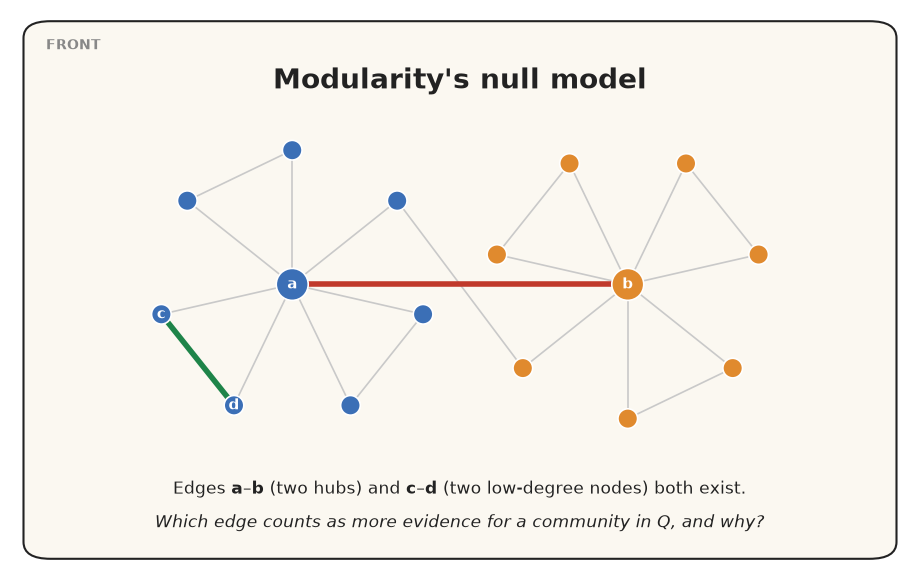

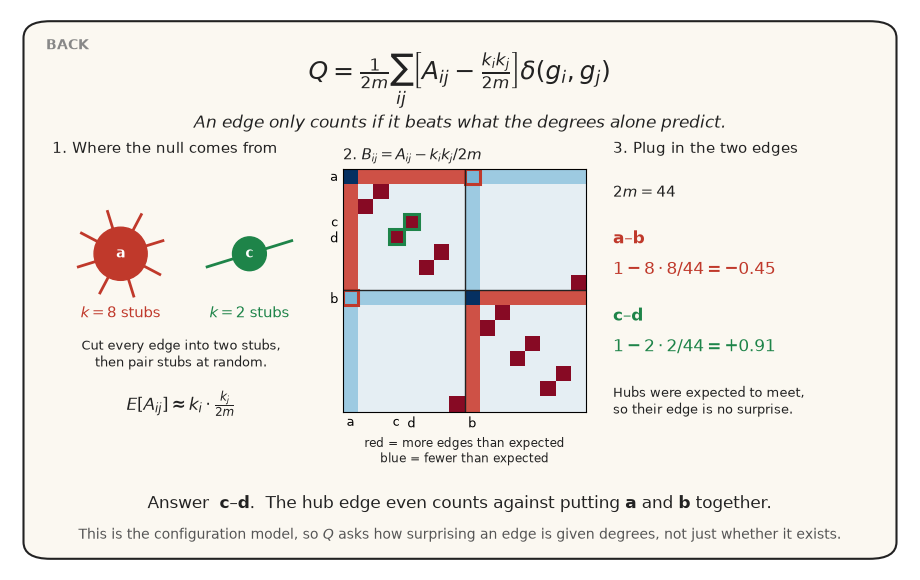

In [24]:
# ---------- shared style ----------
BLUE, ORANGE, GREY, INK, PAPER = "#3b6fb6", "#e08a2e", "#c9c9c9", "#222222", "#fbf8f1"
HUB_C, LOW_C = "#c0392b", "#1e8449"
grp_color = {}
for v in A_nodes:
    grp_color[v] = BLUE
for v in B_nodes:
    grp_color[v] = ORANGE

def card(fig, label):
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_axis_off()
    ax.add_patch(FancyBboxPatch((0.015, 0.02), 0.97, 0.96, boxstyle="round,pad=0,rounding_size=0.03",
                                transform=ax.transAxes, fc=PAPER, ec=INK, lw=1.5))
    ax.text(0.04, 0.93, label, transform=ax.transAxes, fontsize=10, color="#888888", weight="bold")
    return ax

def draw_net(ax, highlight=True):
    ax.set_axis_off(); ax.set_aspect("equal")
    plain = [e for e in G.edges() if set(e) not in ({hub_a, hub_b}, {c, d})]
    nx.draw_networkx_edges(G, pos, edgelist=plain, ax=ax, edge_color=GREY, width=1.2)
    if highlight:
        nx.draw_networkx_edges(G, pos, edgelist=[(hub_a, hub_b)], ax=ax, edge_color=HUB_C, width=4)
        nx.draw_networkx_edges(G, pos, edgelist=[(c, d)], ax=ax, edge_color=LOW_C, width=4)
    sizes = [90 + 55 * deg[v] for v in G]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[grp_color[v] for v in G], node_size=sizes,
                           edgecolors="white", linewidths=1.2)
    nx.draw_networkx_labels(G, pos, ax=ax, labels={hub_a: "a", hub_b: "b", c: "c", d: "d"},
                            font_color="white", font_weight="bold", font_size=11)

# ================= FRONT =================
front = plt.figure(figsize=(9, 5.6), facecolor="white")
card(front, "FRONT")
front.text(0.5, 0.86, "Modularity's null model", ha="center", fontsize=20, weight="bold", color=INK)
axn = front.add_axes([0.08, 0.22, 0.84, 0.58]); draw_net(axn)
front.text(0.5, 0.135, r"Edges $\mathbf{a}$–$\mathbf{b}$ (two hubs) and $\mathbf{c}$–$\mathbf{d}$ (two low-degree nodes) both exist.",
           ha="center", fontsize=12.5, color=INK)
front.text(0.5, 0.075, r"Which edge counts as more evidence for a community in $Q$, and why?",
           ha="center", fontsize=12.5, color=INK, style="italic")

# ================= BACK =================
back = plt.figure(figsize=(9, 5.6), facecolor="white")
card(back, "BACK")
back.text(0.5, 0.875, r"$Q=\frac{1}{2m}\sum_{ij}\left[A_{ij}-\frac{k_i k_j}{2m}\right]\delta(g_i,g_j)$",
          ha="center", fontsize=18, color=INK)
back.text(0.5, 0.79, "An edge only counts if it beats what the degrees alone predict.",
          ha="center", fontsize=12, color=INK, style="italic")

# (1) stub matching
ax1 = back.add_axes([0.04, 0.27, 0.30, 0.46]); ax1.set_axis_off(); ax1.set_aspect("equal")
ax1.set_xlim(-1.6, 1.6); ax1.set_ylim(-1.7, 1.5)
for (x, k, col, name) in [(-0.75, deg[hub_a], HUB_C, "a"), (0.85, deg[c], LOW_C, "c")]:
    for t in np.linspace(0, 2 * np.pi, k, endpoint=False):
        ax1.plot([x, x + 0.55 * np.cos(t + 0.3)], [0.35, 0.35 + 0.55 * np.sin(t + 0.3)], color=col, lw=2)
    ax1.add_patch(Circle((x, 0.35), 0.17 + 0.02 * k, color=col, zorder=3))
    ax1.text(x, 0.35, name, ha="center", va="center", color="white", weight="bold", zorder=4)
    ax1.text(x, -0.45, f"$k={k}$ stubs", ha="center", fontsize=10.5, color=col)
ax1.text(0, -1.05, "Cut every edge into two stubs,\nthen pair stubs at random.", ha="center", fontsize=9.5, color=INK)
ax1.text(0, -1.6, r"$E[A_{ij}]\approx k_i\cdot\frac{k_j}{2m}$", ha="center", fontsize=12, color=INK)
ax1.set_title("1. Where the null comes from", fontsize=10.5, color=INK, loc="left")

# (2) modularity matrix heatmap
ax2 = back.add_axes([0.37, 0.27, 0.27, 0.46])
order = A_nodes + B_nodes
Adj = nx.to_numpy_array(G, nodelist=order); k = Adj.sum(1)
Bmat = Adj - np.outer(k, k) / two_m
ax2.imshow(Bmat, cmap="RdBu_r", vmin=-1, vmax=1)
ax2.axhline(7.5, color=INK, lw=1); ax2.axvline(7.5, color=INK, lw=1)
idx = {v: n for n, v in enumerate(order)}
ticks = [idx[hub_a], idx[c], idx[d], idx[hub_b]]
ax2.set_xticks(ticks)
ax2.set_yticks(ticks)
ax2.set_xticklabels(["a", "c", "d", "b"], fontsize=9); ax2.set_yticklabels(["a", "c", "d", "b"], fontsize=9)
ax2.tick_params(length=0)
for (i, j), col in [((hub_a, hub_b), HUB_C), ((c, d), LOW_C)]:
    for (r, q) in [(idx[i], idx[j]), (idx[j], idx[i])]:
        ax2.add_patch(Rectangle((q - 0.5, r - 0.5), 1, 1, fill=False, ec=col, lw=2.2))
ax2.set_title(r"2. $B_{ij}=A_{ij}-k_ik_j/2m$", fontsize=10.5, color=INK, loc="left")
ax2.text(0.5, -0.1, "red = more edges than expected\nblue = fewer than expected", transform=ax2.transAxes,
         ha="center", va="top", fontsize=8.5, color=INK)

# (3) the two edges
ax3 = back.add_axes([0.67, 0.27, 0.30, 0.46]); ax3.set_axis_off()
ax3.set_xlim(0, 1); ax3.set_ylim(0, 1)
ax3.set_title("3. Plug in the two edges", fontsize=10.5, color=INK, loc="left")
ax3.text(0.0, 0.86, rf"$2m={two_m}$", fontsize=11, color=INK)
ax3.text(0.0, 0.68, r"$\mathbf{a}$–$\mathbf{b}$", fontsize=12, color=HUB_C)
ax3.text(0.0, 0.56, f"$1 - {deg[hub_a]} \\cdot {deg[hub_b]} / {two_m} = {B_hub:+.2f}$", fontsize=12, color=HUB_C)
ax3.text(0.0, 0.38, r"$\mathbf{c}$–$\mathbf{d}$", fontsize=12, color=LOW_C)
ax3.text(0.0, 0.26, f"$1 - {deg[c]} \\cdot {deg[d]} / {two_m} = {B_cd:+.2f}$", fontsize=12, color=LOW_C)
ax3.text(0.0, 0.02, "Hubs were expected to meet,\nso their edge is no surprise.", fontsize=9.5, color=INK)

back.text(0.5, 0.11, r"Answer  $\mathbf{c}$–$\mathbf{d}$.  The hub edge even counts against putting $\mathbf{a}$ and $\mathbf{b}$ together.",
          ha="center", fontsize=12, color=INK)
back.text(0.5, 0.055, r"This is the configuration model, so $Q$ asks how surprising an edge is given degrees, not just whether it exists.",
          ha="center", fontsize=10, color="#555555")

plt.show()

4.

I use the same polblogs graph `g` from Question 1, turned into an undirected networkx graph without self-loops.

In [25]:
# polblogs largest component from Question 1 (graph-tool) -> undirected networkx graph
G = nx.Graph()
G.add_edges_from(g.iter_edges())
G.remove_edges_from(nx.selfloop_edges(G))
N = G.number_of_nodes()
A = nx.to_scipy_sparse_array(G, nodelist=range(N), format="csr")   # row i = node i
k = A.sum(axis=1)                               # degrees
print(N, "nodes,", G.number_of_edges(), "edges")


def run_sis(A, beta, mu, n_total, rng, T=1500, last=500):
    # one SIS run (class_13 rule), all nodes update at the same time
    # each infected neighbour infects with prob beta -> with n infected neighbours: 1-(1-beta)^n
    # returns infected / n_total, averaged over the last 500 steps
    n = A.shape[0]
    infected = np.zeros(n, dtype=bool)
    infected[rng.choice(n, n // 2, replace=False)] = True   # start with half infected
    counts = np.zeros(T)                                     # stays 0 after the epidemic dies out
    for t in range(T):
        n_inf_nbrs = A @ infected                            # number of infected neighbours
        p_infect = 1 - (1 - beta) ** n_inf_nbrs
        new_inf = ~infected & (rng.random(n) < p_infect)
        recover = infected & (rng.random(n) < mu)
        infected = (infected | new_inf) & ~recover
        counts[t] = infected.sum()
        if counts[t] == 0:
            break
    return counts[-last:].mean() / n_total


def largest_eigenvalue(A):
    if A.nnz == 0:          # no edges left
        return 0.0
    return eigsh(A.astype(float), k=1, which="LA")[0][0]

1222 nodes, 16714 edges


1/<k> = 0.0366,  <k>/<k^2> = 0.0123,  1/lambda_1 = 0.0135


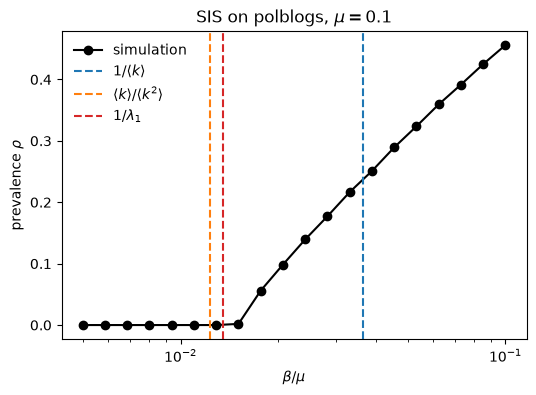

beta/mu = 0.0050   rho = 0.000
beta/mu = 0.0059   rho = 0.000
beta/mu = 0.0069   rho = 0.000
beta/mu = 0.0080   rho = 0.000
beta/mu = 0.0094   rho = 0.000
beta/mu = 0.0110   rho = 0.000
beta/mu = 0.0129   rho = 0.000
beta/mu = 0.0151   rho = 0.002
beta/mu = 0.0177   rho = 0.056
beta/mu = 0.0207   rho = 0.099
beta/mu = 0.0242   rho = 0.140
beta/mu = 0.0283   rho = 0.177
beta/mu = 0.0332   rho = 0.217
beta/mu = 0.0388   rho = 0.251
beta/mu = 0.0455   rho = 0.289
beta/mu = 0.0532   rho = 0.324
beta/mu = 0.0623   rho = 0.359
beta/mu = 0.0730   rho = 0.392
beta/mu = 0.0854   rho = 0.425
beta/mu = 0.1000   rho = 0.456


In [26]:
mu = 0.1
lam1 = largest_eigenvalue(A)
th_k = 1 / k.mean()                  # well-mixed guess
th_hmf = k.mean() / (k**2).mean()    # Pastor-Satorras & Vespignani
th_eig = 1 / lam1                    # Wang et al.
print(f"1/<k> = {th_k:.4f},  <k>/<k^2> = {th_hmf:.4f},  1/lambda_1 = {th_eig:.4f}")

ratios = np.logspace(np.log10(0.005), np.log10(0.1), 20)   # beta/mu values
rng = np.random.default_rng(0)
rho_a = []
for r in ratios:
    rho_a.append(np.mean([run_sis(A, r * mu, mu, N, rng) for _ in range(10)]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ratios, rho_a, "o-", color="black", label="simulation")
ax.axvline(th_k, ls="--", color="tab:blue", label=r"$1/\langle k\rangle$")
ax.axvline(th_hmf, ls="--", color="tab:orange", label=r"$\langle k\rangle/\langle k^2\rangle$")
ax.axvline(th_eig, ls="--", color="tab:red", label=r"$1/\lambda_1$")
ax.set_xscale("log")
ax.set_xlabel(r"$\beta/\mu$")
ax.set_ylabel(r"prevalence $\rho$")
ax.set_title(r"SIS on polblogs, $\mu=0.1$")
ax.legend(frameon=False)
plt.show()

for r, p in zip(ratios, rho_a):
    print(f"beta/mu = {r:.4f}   rho = {p:.3f}")

**(a)** The epidemic dies out for $\beta/\mu$ up to about 0.013. At 0.015 only a tiny fraction of nodes is infected ($\rho\approx0.002$), and above that $\rho$ keeps growing. So in my simulation the threshold is between about 0.013 and 0.015.

- $1/\langle k\rangle \approx 0.037$ is much too high. At this value more than 20% of the nodes are already infected.
- $\langle k\rangle/\langle k^2\rangle \approx 0.012$ is close, just a little too low.
- $1/\lambda_1 \approx 0.0135$ falls right where the epidemic starts, so it is the best prediction.

So the threshold on a network is much lower than the well-mixed guess. The reason is that polblogs has some hubs with very high degree, and the hubs keep the disease alive even when $\beta$ is small. The predictions with $\langle k^2\rangle$ and $\lambda_1$ take the hubs into account, so they work much better than the one that only uses the average degree.

In [27]:
beta = 0.05 * mu
g_list = np.round(np.arange(0, 0.81, 0.05), 2)
max_remove = int(0.8 * N)
degree_order = list(np.argsort(-k))      # highest degree first (original network)


def immunization_order(strategy, rng):
    # order in which nodes get immunized; for each g we remove the first g*N nodes,
    # so nodes immunized at a small g stay immunized at a larger g
    if strategy == "random":
        return list(rng.permutation(N))
    if strategy == "targeted":
        return degree_order
    # acquaintance: pick a random node, then immunize one of its neighbours at random
    order = []
    while len(order) < max_remove:
        i = rng.integers(N)
        j = rng.choice(list(G.neighbors(i)))
        if j not in order:
            order.append(j)
    return order


strategies = ["random", "targeted", "acquaintance"]
rho_b = {s: np.zeros((10, len(g_list))) for s in strategies}     # rows = runs
inv_lam = {s: np.zeros((10, len(g_list))) for s in strategies}

for s in strategies:
    for run in range(10):
        rng = np.random.default_rng(100 + run)
        order = immunization_order(s, rng)
        for gi, frac in enumerate(g_list):
            removed = set(order[:int(round(frac * N))])
            keep = [i for i in range(N) if i not in removed]
            A_left = A[keep][:, keep]                       # network after deleting immunized nodes
            rho_b[s][run, gi] = run_sis(A_left, beta, mu, N, rng)   # divide by all N nodes
            lam = largest_eigenvalue(A_left)
            inv_lam[s][run, gi] = np.inf if lam == 0 else 1 / lam
    print(s, "done")

random done
targeted done
acquaintance done


random        epidemic stops at g = 0.7,  1/lambda_1 >= beta/mu at g = 0.75
targeted      epidemic stops at g = 0.1,  1/lambda_1 >= beta/mu at g = 0.15
acquaintance  epidemic stops at g = 0.25,  1/lambda_1 >= beta/mu at g = 0.3


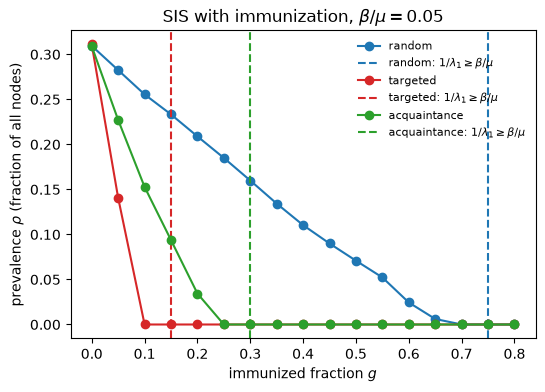

In [28]:
colors = {"random": "tab:blue", "targeted": "tab:red", "acquaintance": "tab:green"}
fig, ax = plt.subplots(figsize=(6, 4))
for s in strategies:
    ax.plot(g_list, rho_b[s].mean(axis=0), "o-", color=colors[s], label=s)

    # i. first g where all 10 runs died out
    died = np.where((rho_b[s] == 0).all(axis=0))[0]
    # iv. first g where the median 1/lambda_1 reaches beta/mu
    med = np.median(inv_lam[s], axis=0)
    cross = np.where(med >= beta / mu)[0]
    if len(cross) > 0:
        ax.axvline(g_list[cross[0]], ls="--", color=colors[s], label=f"{s}: " + r"$1/\lambda_1 \geq \beta/\mu$")

    print(f"{s:13s} epidemic stops at g = {g_list[died[0]] if len(died) else 'not in range'},"
          f"  1/lambda_1 >= beta/mu at g = {g_list[cross[0]] if len(cross) else 'not in range'}")

ax.set_xlabel("immunized fraction $g$")
ax.set_ylabel(r"prevalence $\rho$ (fraction of all nodes)")
ax.set_title(r"SIS with immunization, $\beta/\mu=0.05$")
ax.legend(frameon=False, fontsize=8)
plt.show()

**(b)**

**i.** The first tested $g$ where all 10 runs died out is $g=0.10$ for targeted, $g=0.25$ for acquaintance, and $g=0.70$ for random immunization.

**ii.** When we pick a random node and then one of its neighbours, we do not pick nodes with equal chance. A node with degree $k$ is the neighbour of $k$ nodes, so it gets picked about $k$ times more often. This is the friendship paradox (your friends have more friends than you). So acquaintance immunization finds the hubs much more often than random immunization, even though it never measures degree. Random immunization mostly hits low-degree nodes, and removing them barely changes the network.

**iii.**
- *Random* is easy to use. It only needs a list of people. But here it needs about 70% coverage, which is very costly.
- *Targeted* works best but needs the whole network, because we have to know everyone's number of contacts. In a real population we almost never have this.
- *Acquaintance* only needs each chosen person to name one contact. No one needs to know the full network. So acquaintance immunization is the one we could really use, and it is much better than random.

**iv.** The median $1/\lambda_1$ reaches $\beta/\mu=0.05$ at $g=0.15$ for targeted, $g=0.30$ for acquaintance, and $g=0.75$ for random. So $1/\lambda_1$ predicts the right order of the three strategies and gets close to where the epidemic stops. But for all three strategies it is one step ($0.05$) later than the simulation, so it is a bit conservative. The theory says the disease dies out when $\beta/\mu < 1/\lambda_1$, but in the simulation it can die out a little before that point, because near the threshold the epidemic is small and can die by chance in a finite network.

## AI use

I used Claude (Anthropic, Claude Opus 5.5) as a helper in this assignment. For every question I ran all the code myself and checked the results.

- **Question 1(a).** I wrote the code myself and used Claude for debugging.
- **Question 1(b)–(d).** Claude helped me write the graph-tool code and fix errors. It also helped me read Peixoto's paper and draft the summary in (d), which I then edited.
- **Question 2.** Claude helped me understand the question and write the commute time code. It also helped me find a bug with the edge weights in `karate_club_graph`.
- **Question 3.** I chose the topic (the null model of modularity). Claude helped me write the flashcard code and gave feedback on my explanation.
- **Question 4.** Claude helped me write the SIS simulation and immunization code and check my interpretation of the results.

## References

- Adamic, L. A., & Glance, N. (2005). The political blogosphere and the 2004 U.S. election: Divided they blog. *Proceedings of the 3rd International Workshop on Link Discovery*, 36–43.
- Cohen, R., Havlin, S., & ben-Avraham, D. (2003). Efficient immunization strategies for computer networks and populations. *Physical Review Letters*, 91(24), 247901.
- Guimerà, R., Sales-Pardo, M., & Amaral, L. A. N. (2004). Modularity from fluctuations in random graphs and complex networks. *Physical Review E*, 70(2), 025101.
- Masuda, N., Porter, M. A., & Lambiotte, R. (2017). Random walks and diffusion on networks. *Physics Reports*, 716, 1–58.
- Newman, M. E. J. (2006). Modularity and community structure in networks. *PNAS*, 103(23), 8577–8582.
- Pastor-Satorras, R., & Vespignani, A. (2002). Epidemic dynamics in finite size scale-free networks. *Physical Review E*, 65(3), 035108.
- Peixoto, T. P. (2019). Bayesian stochastic blockmodeling. In *Advances in Network Clustering and Blockmodeling* (pp. 289–332). Wiley. arXiv:1705.10225.
- Wang, Y., Chakrabarti, D., Wang, C., & Faloutsos, C. (2003). Epidemic spreading in real networks: An eigenvalue viewpoint. *Proceedings of the 22nd International Symposium on Reliable Distributed Systems*, 25–34.